In [1]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# PSFCH reception errors: sensitivity of the cooperative protocol

**The question.** Campaign v3 delivers every PSFCH (ACK/NACK) without error. Every decision of the cooperative
protocol is driven by that feedback: the helper relays only while a member still NACKs, the source takes over on a
helper NACK, falls back when the helper stays silent, and stops when all members ACK. What happens when feedback
is lost or misread?

**How a PSFCH error acts in the model** (`nack_only_harq.cc`): the source declares success only if *every* member
ACKed; a missing feedback (DTX) counts as NACK. A **lost** feedback therefore costs an extra transmission (a lost
ACK) or a later recovery (a lost helper NACK is caught by the fallback check), but cannot end a TB early. A
**NACK detected as ACK** can: if it completes the set of ACKs, the source stops and that member loses the TB.

**3GPP PSFCH vs 5G-LENA** (TS 38.211 V17.11.0 §8.3.4, TS 38.213 V17.14.0 §16.2.3, §16.3):

| | 3GPP Rel-17 | 5G-LENA (stock) |
|---|---|---|
| waveform | format 0: 12-subcarrier sequence, ACK/NACK by cyclic shift (NACK $m_{cs}$=0, ACK 6) | a message on the signal |
| bandwidth | 1 PRB per feedback (`sl-PSFCH-RB-Set`) | every PRB of the pool (50) |
| symbols | second-to-last SL symbol, repeated in the symbol before (AGC), then a guard | 1 symbol |
| multiplexing | orthogonal: resource $(P_{ID}+M_{ID}) \bmod R$ over PRBs × cyclic-shift pairs | all PSFCH overlap and interfere |
| power (no `dl-P0-PSFCH`) | $P_{CMAX} - 10\log_{10} N_{Tx,PSFCH}$ on that PRB | 23 dBm spread over 50 PRBs (−17 dB per PRB) |

**What is swept** (`NrSpectrumPhy` attributes, `patches/nr/local.patch`; each run is the v3 command of the same
arm, cell and seed plus these flags; every UE draws on its own stream, so the leader and the helper overhearing the
members both see the errors):

| setting | attributes | meaning | arms |
|---|---|---|---|
| `miss<p>` | mode 1, `SlPsfchMissProb` = 1, 5, 10, 20, 30 % | each received ACK/NACK lost (read as DTX) | R6 (R3 at 10 %) |
| `n2a<q>` | mode 1, `SlPsfchNackToAckProb` = 0.1, 1, 5 % | a received NACK detected as ACK | R6 (R3 at 1 %) |
| `snr_p<P>` | mode 2, `SlPsfchTxPowerDbm` = 23, 10, 0 dBm | the PSFCH at the 3GPP power on one PRB, decoded like a PSCCH of the same link (NrEesmIrT1, MCS 0) over noise; other PSFCH orthogonal; a failed PSFCH is lost | R6 (R3 at 23 dBm) |

23 dBm is $P_{CMAX}$, the out-of-coverage PSFCH power; 10 and 0 dBm stand for in-coverage open-loop power control.
Cells: 3 routes × 2 traffic types × 0 / 60 background vehicles, seeds 1–10. Reference: campaign v3 (error-free),
which the new build reproduces bit for bit with the flags off (`psfch_err_sweep.py check`, laptop and ease-rtx).

**Limits.** Format-0 detection is a sequence correlation, here replaced by the PSCCH decoding model on one PRB.
The AGC repeat adds no energy. DTX detected as ACK (a silent member read as ACK) is not modelled. Mode 1 errors
are independent per feedback (no correlation with the link).

In [2]:
import glob, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
FIG = 'figures/psfch_err'; os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'font.family': 'serif', 'axes.grid': True, 'grid.alpha': 0.3})
# paper palette (draw.io protocol figure): source = blue, cooperative = sage, ACK = green, NACK = red
ARM = {'R3': '#3E7CA6', 'R6': '#4F7D69'}
SCN = {'hwy': 'Highway', 'rbt': 'Roundabout W', 'rbtE': 'Roundabout E'}
MK = {'hwy': 'o', 'rbt': 's', 'rbtE': '^'}
d = pd.read_csv('out/psfch_err/summary.csv')
d['seed'] = d.cell.str.extract(r'_s(\d+)$').astype(int)[0]
d['cell'] = d.cell.str.replace(r'_s\d+$', '', regex=True)
v = []
for arm in ('R3', 'R6'):
    for (cell, seed) in d[['cell', 'seed']].drop_duplicates().itertuples(index=False):
        f = glob.glob(f'out/remote_v3/{arm}/{cell}_s{seed}_run.csv*')
        if f:
            v.append(pd.read_csv(f[0]).iloc[0].to_dict() | {'arm': arm, 'cell': cell, 'seed': seed, 'setting': 'v3'})
v = pd.DataFrame(v)
for x in (d, v):
    x['bg'] = np.where(x.cell.str.contains('moderate'), 60, 0)
    x['sc'] = x.cell.str.split('_').str[0]
    x['tr'] = np.where(x.cell.str.contains('aperiodic'), 'aperiodic', 'periodic')
print(len(d), 'sweep runs,', len(v), 'error-free v3 runs')
d.groupby(['arm', 'setting']).size().unstack(0)

1680 sweep runs, 240 error-free v3 runs


arm,R3,R6
setting,,
miss0.01,NaN,120.0
miss0.05,NaN,120.0
miss0.1,120.0,120.0
miss0.2,NaN,120.0
miss0.3,NaN,120.0
n2a0.001,NaN,120.0
n2a0.01,120.0,120.0
n2a0.05,NaN,120.0
snr_p0,NaN,120.0


## 1. Realised PSFCH error rates

Fraction of the platoon's feedback received at the leader (and at the members, who overhear it) that was lost,
and NACKs detected as ACK per received feedback. For the forced settings it must match the setting.

In [3]:
g = d.groupby(['arm', 'setting', 'bg'])
R = pd.DataFrame({'lost at leader (%)': 100 * g.psfch_lost_leader.sum() / g.psfch_fb_leader.sum(),
                  'lost at members (%)': 100 * g.psfch_lost_members.sum() / g.psfch_fb_members.sum(),
                  'NACK->ACK at leader (per 1000 fb)': 1000 * g.psfch_n2a_leader.sum() / g.psfch_fb_leader.sum()})
R.round(3).unstack('bg')

lost at leader (%)         lost at members (%)          \
bg                           0       60                  0       60   
arm setting                                                           
R3  miss0.1               9.963   9.988              10.175  10.115   
    n2a0.01               0.000   0.000               0.000   0.000   
    snr_p23               0.286   0.229               0.692   0.526   
R6  miss0.01              0.991   1.001               0.992   0.998   
    miss0.05              5.024   5.045               5.050   5.024   
    miss0.1               9.966   9.996              10.147  10.129   
    miss0.2              19.904  19.963              20.305  20.240   
    miss0.3              29.897  29.884              30.225  30.163   
    n2a0.001              0.000   0.000               0.000   0.000   
    n2a0.01               0.000   0.000               0.000   0.000   
    n2a0.05               0.000   0.000               0.000   0.000   
    snr_p0               22.095  18.308              12.968  12.747   
    snr_p10               7.063   5.644               3.641   3.656   
    snr_p23               0.577   0.444               0.267   0.269   

             NACK->ACK at leader (per 1000 fb)         
bg                                          0      60  
arm setting                                            
R3  miss0.1                              0.000  0.000  
    n2a0.01                              1.517  1.874  
    snr_p23                              0.000  0.000  
R6  miss0.01                             0.000  0.000  
    miss0.05                             0.000  0.000  
    miss0.1                              0.000  0.000  
    miss0.2                              0.000  0.000  
    miss0.3                              0.000  0.000  
    n2a0.001                             0.104  0.177  
    n2a0.01                              1.459  1.884  
    n2a0.05                              7.470  8.979  
    snr_p0                               0.000  0.000  
    snr_p10                              0.000  0.000  
    snr_p23                              0.000  0.000

### SNR mode: loss rate by route, load and power

The loss depends on the link through the received power (distance, buildings, fading). The leader's mean
PSFCH error rate per route:

In [4]:
s = d[d.setting.str.startswith('snr')]
T = s.groupby(['setting', 'sc', 'bg']).apply(lambda x: 100 * x.psfch_lost_leader.sum() / x.psfch_fb_leader.sum())
T = T.unstack(['sc', 'bg']).round(2)
T.columns = [f'{SCN[a]}, {b} veh.' for a, b in T.columns]
T

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_76142/786999030.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  T = s.groupby(['setting', 'sc', 'bg']).apply(lambda x: 100 * x.psfch_lost_leader.sum() / x.psfch_fb_leader.sum())


,"Highway, 0 veh.","Highway, 60 veh.","Roundabout W, 0 veh.","Roundabout W, 60 veh.","Roundabout E, 0 veh.","Roundabout E, 60 veh."
setting,,,,,,
snr_p0,12.32,11.40,27.71,21.49,26.59,21.07
snr_p10,2.02,1.81,10.07,7.50,9.06,7.11
snr_p23,0.15,0.14,0.60,0.43,0.51,0.39


## 2. Cost against the error-free protocol (paired by seed)

Change against campaign v3 of the same arm, cell and seed: mean member PRR (pp), worst member PRR (pp) and
transmissions per packet. Mean over the runs ± 95 % Student-t half-width.

In [5]:
K = {'prr_mean': 100, 'prr_min': 100, 'tx_per_pkt': 1}
J = d.merge(v, on=['arm', 'cell', 'seed'], suffixes=('', '_v3'))
def ci(x):
    x = x.dropna()
    return x.mean(), stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
rows = []
for (arm, s, bg), q in J.groupby(['arm', 'setting', 'bg']):
    r = dict(arm=arm, setting=s, bg=bg, runs=len(q))
    for k, f in K.items():
        m, h = ci(f * (q[k] - q[k + '_v3']))
        r[k] = f'{m:+.2f} ± {h:.2f}'
    rows.append(r)
D = pd.DataFrame(rows).set_index(['arm', 'setting', 'bg'])
D

runs      prr_mean       prr_min    tx_per_pkt
arm setting  bg                                                
R3  miss0.1  0     60  -0.05 ± 0.44  -0.82 ± 1.13  +0.23 ± 0.05
             60    60  -0.03 ± 0.44  -0.31 ± 1.03  +0.16 ± 0.04
    n2a0.01  0     60  -0.02 ± 0.32  -0.32 ± 0.62  -0.00 ± 0.01
             60    60  -0.00 ± 0.43  -0.16 ± 0.64  +0.00 ± 0.01
    snr_p23  0     60  -0.05 ± 0.36  -0.89 ± 1.10  -0.00 ± 0.01
             60    60  -0.02 ± 0.30  -0.13 ± 0.70  -0.00 ± 0.01
R6  miss0.01 0     60  -0.01 ± 0.38  +0.63 ± 0.96  +0.04 ± 0.01
             60    60  -0.44 ± 0.48  -1.10 ± 1.05  +0.03 ± 0.02
    miss0.05 0     60  +0.11 ± 0.41  +1.02 ± 1.07  +0.20 ± 0.03
             60    60  -0.20 ± 0.43  -0.33 ± 0.94  +0.13 ± 0.03
    miss0.1  0     60  -0.07 ± 0.39  +0.73 ± 1.09  +0.36 ± 0.05
             60    60  -0.36 ± 0.57  -1.21 ± 0.90  +0.23 ± 0.04
    miss0.2  0     60  -0.25 ± 0.47  +0.13 ± 1.20  +0.52 ± 0.07
             60    60  -0.62 ± 0.46  -1.35 ± 0.98  +0.33 ± 0.06
    miss0.3  0     60  -0.39 ± 0.39  -0.09 ± 1.05  +0.60 ± 0.09
             60    60  -0.78 ± 0.58  -1.39 ± 1.18  +0.37 ± 0.07
    n2a0.001 0     60  -0.00 ± 0.01  +0.02 ± 0.02  +0.00 ± 0.00
             60    60  -0.02 ± 0.18  +0.09 ± 0.45  +0.00 ± 0.00
    n2a0.01  0     60  +0.11 ± 0.30  +0.63 ± 0.92  +0.00 ± 0.01
             60    60  +0.08 ± 0.45  +0.19 ± 1.16  +0.00 ± 0.01
    n2a0.05  0     60  -0.04 ± 0.32  +0.17 ± 1.01  -0.01 ± 0.01
             60    60  -0.16 ± 0.48  -0.51 ± 1.04  -0.01 ± 0.01
    snr_p0   0     60  -0.35 ± 0.49  -0.05 ± 1.03  +0.19 ± 0.04
             60    60  -0.26 ± 0.49  -0.40 ± 0.98  +0.12 ± 0.03
    snr_p10  0     60  +0.28 ± 0.45  +0.66 ± 1.09  +0.03 ± 0.01
             60    60  -0.30 ± 0.56  -0.50 ± 1.12  +0.02 ± 0.01
    snr_p23  0     60  -0.10 ± 0.34  +0.02 ± 0.81  +0.01 ± 0.01
             60    60  -0.07 ± 0.43  -0.24 ± 0.92  -0.00 ± 0.01

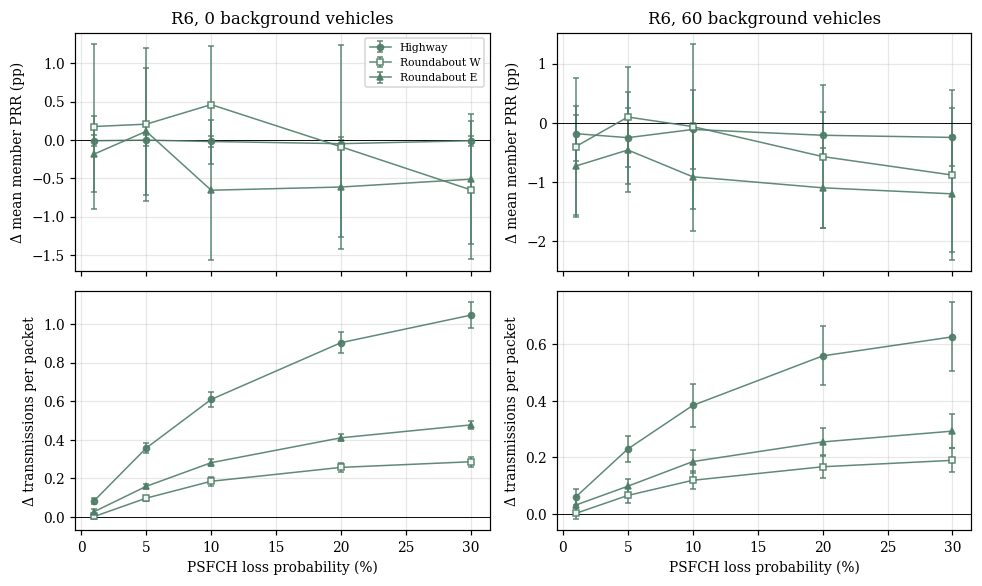

In [6]:
def curve(prefix, xs, label, fname):
    fig, axs = plt.subplots(2, 2, figsize=(9, 5.4), sharex=True)
    for j, bg in enumerate((0, 60)):
        for i, (k, f, yl) in enumerate([('prr_mean', 100, 'Δ mean member PRR (pp)'),
                                        ('tx_per_pkt', 1, 'Δ transmissions per packet')]):
            ax = axs[i, j]
            for sc in SCN:
                m, h = [], []
                for x in xs:
                    q = J[(J.arm == 'R6') & (J.setting == f'{prefix}{x}') & (J.bg == bg) & (J.sc == sc)]
                    a, b = ci(f * (q[k] - q[k + '_v3'])) if len(q) else (np.nan, np.nan)
                    m.append(a); h.append(b)
                ax.errorbar(100 * np.array(xs, float), m, yerr=h, marker=MK[sc], ms=4, capsize=2, lw=1,
                            color=ARM['R6'], alpha=.9, label=SCN[sc], mfc='white' if sc == 'rbt' else ARM['R6'])
            ax.axhline(0, color='k', lw=.6)
            ax.set_ylabel(yl)
            if i == 0: ax.set_title(f'R6, {bg} background vehicles')
            if i == 1: ax.set_xlabel(label)
    axs[0, 0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(f'{FIG}/{fname}.pdf'); plt.show()
curve('miss', [0.01, 0.05, 0.1, 0.2, 0.3], 'PSFCH loss probability (%)', 'r6_vs_loss')

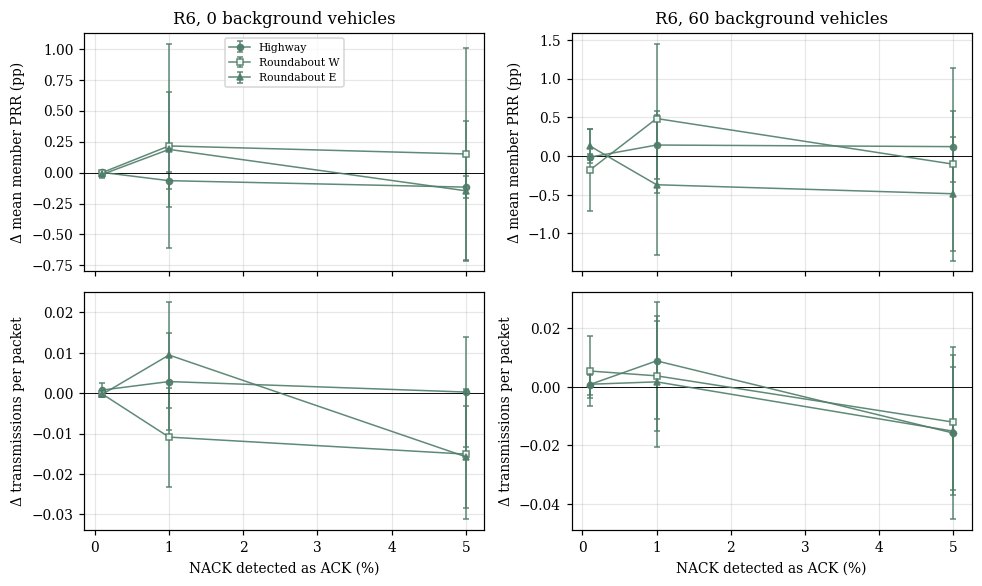

In [7]:
curve('n2a', [0.001, 0.01, 0.05], 'NACK detected as ACK (%)', 'r6_vs_nack_to_ack')

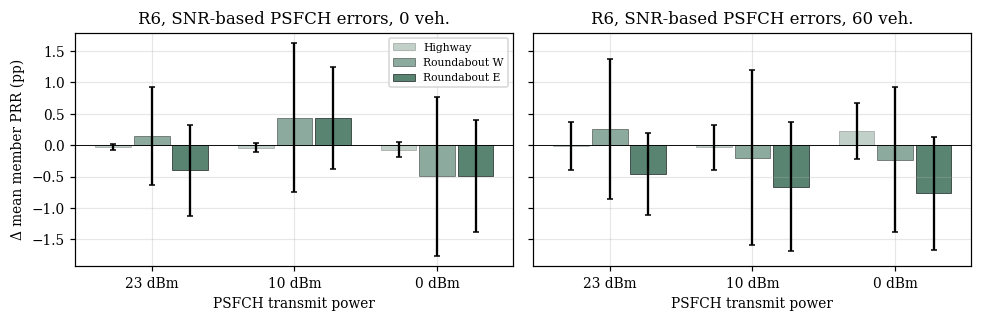

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.0), sharey=True)
P = ['snr_p23', 'snr_p10', 'snr_p0']
for j, bg in enumerate((0, 60)):
    ax = axs[j]
    for i, sc in enumerate(SCN):
        m, h = zip(*[ci(100 * (q.prr_mean - q.prr_mean_v3)) for p in P
                      for q in [J[(J.arm == 'R6') & (J.setting == p) & (J.bg == bg) & (J.sc == sc)]]])
        ax.bar(np.arange(3) + (i - 1) * .27, m, .25, yerr=h, capsize=2, color=ARM['R6'], alpha=.35 + .3 * i,
               edgecolor='k', lw=.4, label=SCN[sc])
    ax.set_xticks(range(3)); ax.set_xticklabels(['23 dBm', '10 dBm', '0 dBm']); ax.axhline(0, color='k', lw=.6)
    ax.set_title(f'R6, SNR-based PSFCH errors, {bg} veh.'); ax.set_xlabel('PSFCH transmit power')
axs[0].set_ylabel('Δ mean member PRR (pp)'); axs[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/r6_vs_power.pdf'); plt.show()

### Per route, traffic and load

The table above pools the six route × traffic cells of a load. Here R6 per cell (10 paired seeds each): Δ mean
member PRR (pp), Δ worst member PRR (pp) and Δ transmissions per packet against v3; `*` = the 95 % interval
excludes 0. Last column: transmissions per packet without errors.

In [9]:
SETS = ['snr_p23', 'snr_p10', 'snr_p0', 'miss0.1', 'miss0.3', 'n2a0.05']
def cell_ci(x, f):
    m, h = ci(f * x)
    return f'{m:+.2f} ± {h:.2f}' + ('*' if abs(m) > h else ' ')
rows = []
for s in SETS:
    for (sc, tr, bg), q in J[(J.arm == 'R6') & (J.setting == s)].groupby(['sc', 'tr', 'bg']):
        rows.append({'setting': s, 'route': SCN[sc], 'traffic': tr, 'bg': bg,
                     'Δ prr_mean (pp)': cell_ci(q.prr_mean - q.prr_mean_v3, 100),
                     'Δ prr_min (pp)': cell_ci(q.prr_min - q.prr_min_v3, 100),
                     'Δ tx/pkt': cell_ci(q.tx_per_pkt - q.tx_per_pkt_v3, 1),
                     'tx/pkt v3': round(q.tx_per_pkt_v3.mean(), 2)})
PC = pd.DataFrame(rows).set_index(['setting', 'route', 'traffic', 'bg'])
sig = {k: PC[k].str.endswith('*').groupby(level='setting').sum() for k in ('Δ prr_mean (pp)', 'Δ prr_min (pp)', 'Δ tx/pkt')}
display(pd.DataFrame(sig).loc[SETS].rename(columns=lambda c: f'{c}: cells with *').assign(cells=12))
with pd.option_context('display.max_rows', 200):
    display(PC)

,Δ prr_mean (pp): cells with *,Δ prr_min (pp): cells with *,Δ tx/pkt: cells with *,cells
setting,,,,
snr_p23,0,0,1,12
snr_p10,0,0,3,12
snr_p0,1,1,10,12
miss0.1,0,1,12,12
miss0.3,1,2,12,12
n2a0.05,1,0,0,12


Δ prr_mean (pp) Δ prr_min (pp)  \
setting route        traffic   bg                                  
snr_p23 Highway      aperiodic 0    -0.03 ± 0.10   +0.04 ± 0.55    
                               60   -0.12 ± 0.78   -0.33 ± 1.59    
                     periodic  0    -0.03 ± 0.06   -0.18 ± 0.29    
                               60   +0.08 ± 0.31   +0.28 ± 0.80    
        Roundabout W aperiodic 0    +0.27 ± 1.58   -0.15 ± 2.68    
                               60   +0.49 ± 1.93   +0.88 ± 2.55    
                     periodic  0    +0.02 ± 0.67   +1.00 ± 2.71    
                               60   +0.02 ± 1.52   +0.15 ± 4.69    
        Roundabout E aperiodic 0    -0.57 ± 1.34   -1.32 ± 3.60    
                               60   -0.60 ± 1.19   -1.32 ± 2.16    
                     periodic  0    -0.23 ± 0.86   +0.70 ± 1.88    
                               60   -0.31 ± 0.81   -1.09 ± 1.95    
snr_p10 Highway      aperiodic 0    -0.02 ± 0.16   -0.12 ± 0.85    
                               60   -0.09 ± 0.70   -0.47 ± 1.68    
                     periodic  0    -0.05 ± 0.05   -0.28 ± 0.38    
                               60   +0.02 ± 0.35   -0.38 ± 1.26    
        Roundabout W aperiodic 0    +0.77 ± 2.31   +1.76 ± 4.76    
                               60   +0.05 ± 1.57   +0.82 ± 2.07    
                     periodic  0    +0.10 ± 1.21   -1.45 ± 3.30    
                               60   -0.45 ± 2.66   -0.76 ± 5.16    
        Roundabout E aperiodic 0    +0.24 ± 1.55   +1.14 ± 2.29    
                               60   -0.91 ± 1.77   -1.74 ± 2.87    
                     periodic  0    +0.63 ± 0.90   +2.90 ± 3.59    
                               60   -0.42 ± 1.42   -0.47 ± 4.20    
snr_p0  Highway      aperiodic 0    -0.07 ± 0.26   -0.30 ± 1.35    
                               60   +0.45 ± 0.76   +0.28 ± 1.77    
                     periodic  0    -0.08 ± 0.07*  -0.30 ± 0.40    
                               60   -0.00 ± 0.58   +0.08 ± 1.35    
        Roundabout W aperiodic 0    -1.03 ± 2.43   -0.71 ± 4.59    
                               60   -1.32 ± 1.42   -1.55 ± 1.67    
                     periodic  0    +0.03 ± 1.28   +3.52 ± 2.34*   
                               60   +0.85 ± 1.79   +1.56 ± 4.19    
        Roundabout E aperiodic 0    -0.39 ± 1.75   -1.09 ± 3.18    
                               60   -0.98 ± 1.26   -1.17 ± 2.26    
                     periodic  0    -0.59 ± 0.92   -1.40 ± 2.44    
                               60   -0.56 ± 1.53   -1.62 ± 3.63    
miss0.1 Highway      aperiodic 0    -0.02 ± 0.14   +0.40 ± 0.68    
                               60   +0.08 ± 1.30   -0.31 ± 2.19    
                     periodic  0    -0.02 ± 0.07   -0.14 ± 0.32    
                               60   -0.30 ± 0.72   -1.01 ± 1.87    
        Roundabout W aperiodic 0    +0.43 ± 1.57   +2.48 ± 3.65    
                               60   -0.30 ± 1.69   -0.38 ± 2.13    
                     periodic  0    +0.49 ± 0.68   +2.94 ± 4.51    
                               60   +0.17 ± 2.60   -0.77 ± 3.33    
        Roundabout E aperiodic 0    -0.86 ± 1.89   -1.59 ± 2.61    
                               60   -1.02 ± 1.67   -2.22 ± 3.45    
                     periodic  0    -0.45 ± 0.73   +0.26 ± 3.31    
                               60   -0.80 ± 1.13   -2.59 ± 1.48*   
miss0.3 Highway      aperiodic 0    -0.05 ± 0.13   -0.16 ± 0.81    
                               60   -0.33 ± 1.05   -1.33 ± 2.33    
                     periodic  0    +0.03 ± 0.07   +0.18 ± 0.37    
                               60   -0.16 ± 0.25   -1.01 ± 0.88*   
        Roundabout W aperiodic 0    -1.08 ± 1.87   +0.16 ± 4.09    
                               60   -1.44 ± 1.58   -1.44 ± 3.13    
                     periodic  0    -0.23 ± 0.51   +0.43 ± 4.04    
                               60   -0.33 ± 2.72   +0.54 ± 5.69    
        Roundabout E aperiodic 0    -0.82 ± 1.56   -1.27 ± 2.89    
                      

### Where the extra transmissions come from

`tx_per_pkt` = (leader + helper transmissions) / packets. Split per packet for R6, mean over the 12 cells: the
leader's new TBs and retransmissions (fallback takeovers and takeovers after a helper NACK are among them), the
helper's relays, and the relays sent after every member had already ACKed (`relay_after_allack`: the helper
missed at least one ACK and read it as NACK). The helper overhears the members' PSFCH and draws its own errors, so
it relays on a lost ACK just as the leader would retransmit.

In [10]:
M = {'leader new TB': 'leader_new_tb', 'leader retx': 'leader_retx', '  of which fallback': 'fallback_tx',
     '  of which takeover (helper NACK)': 'helper_reclaim', 'helper relays': 'helper_tx',
     '  of which after all ACKed': 'relay_after_allack'}
def per_pkt(q, sfx=''):
    return {k: (q[c + sfx] / q['pkts' + sfx]).mean() for k, c in M.items()}
r6 = J[J.arm == 'R6']
S = {'v3 (error-free)': per_pkt(r6[r6.setting == 'snr_p23'], '_v3')}
for s in ['snr_p23', 'snr_p10', 'snr_p0', 'miss0.01', 'miss0.05', 'miss0.1', 'miss0.2', 'miss0.3', 'n2a0.05']:
    S[s] = per_pkt(r6[r6.setting == s])
display(pd.DataFrame(S).T.round(3))
rows = []
for s in ['snr_p23', 'miss0.1', 'n2a0.01']:
    for bg in (0, 60):
        r = {'setting': s, 'bg': bg}
        for arm in ('R3', 'R6'):
            q = J[(J.arm == arm) & (J.setting == s) & (J.bg == bg)]
            r[f'{arm} Δ tx/pkt'] = cell_ci(q.tx_per_pkt - q.tx_per_pkt_v3, 1)
        rows.append(r)
print('Extra transmissions per packet under the same errors, R6 against source Option 2 (R3):')
pd.DataFrame(rows).set_index(['setting', 'bg'])

,leader new TB,leader retx,of which fallback,of which takeover (helper NACK),helper relays,of which after all ACKed
v3 (error-free),1.0,0.188,0.072,0.133,1.203,0.000
snr_p23,1.0,0.187,0.076,0.128,1.207,0.002
snr_p10,1.0,0.188,0.105,0.118,1.227,0.022
snr_p0,1.0,0.213,0.203,0.091,1.334,0.133
miss0.01,1.0,0.197,0.102,0.128,1.228,0.030
miss0.05,1.0,0.210,0.155,0.122,1.349,0.145
miss0.1,1.0,0.209,0.169,0.113,1.476,0.263
miss0.2,1.0,0.198,0.162,0.100,1.618,0.415
miss0.3,1.0,0.184,0.145,0.086,1.693,0.492
n2a0.05,1.0,0.187,0.095,0.118,1.192,0.000


Extra transmissions per packet under the same errors, R6 against source Option 2 (R3):


R3 Δ tx/pkt    R6 Δ tx/pkt
setting bg                              
snr_p23 0   -0.00 ± 0.01   +0.01 ± 0.01 
        60  -0.00 ± 0.01   -0.00 ± 0.01 
miss0.1 0   +0.23 ± 0.05*  +0.36 ± 0.05*
        60  +0.16 ± 0.04*  +0.23 ± 0.04*
n2a0.01 0   -0.00 ± 0.01   +0.00 ± 0.01 
        60  +0.00 ± 0.01   +0.00 ± 0.01

## 3. Does the cooperative scheme suffer more than source Option 2?

Both arms use Option 2 feedback, so both are exposed. Cooperative gain R6 − R3 (mean member PRR, pp, paired by
cell and seed) without errors (v3) and under the same errors; a smaller gain means R6 is the more sensitive one.

In [11]:
rows = []
for s in ['v3', 'snr_p23', 'miss0.1', 'n2a0.01']:
    src = v if s == 'v3' else d[d.setting == s]
    p = src.pivot_table(index=['bg', 'cell', 'seed'], columns='arm', values=['prr_mean', 'prr_min'])
    for bg, q in p.groupby(level=0):
        if ('prr_mean', 'R3') not in q or ('prr_mean', 'R6') not in q:
            continue
        r = dict(setting=s, bg=bg, runs=int(q[('prr_mean', 'R6')].notna().sum()))
        for k in ('prr_mean', 'prr_min'):
            m, h = ci(100 * (q[(k, 'R6')] - q[(k, 'R3')]))
            r[f'R6 − R3 {k} (pp)'] = f'{m:+.2f} ± {h:.2f}'
        rows.append(r)
pd.DataFrame(rows).set_index(['setting', 'bg'])

runs R6 − R3 prr_mean (pp) R6 − R3 prr_min (pp)
setting bg                                                 
v3      0     60         +11.92 ± 2.05        +22.70 ± 3.74
        60    60          +9.29 ± 1.88        +19.70 ± 3.32
snr_p23 0     60         +11.87 ± 2.08        +23.60 ± 4.01
        60    60          +9.23 ± 1.89        +19.59 ± 3.25
miss0.1 0     60         +11.90 ± 2.07        +24.25 ± 4.08
        60    60          +8.95 ± 1.93        +18.80 ± 3.40
n2a0.01 0     60         +12.05 ± 2.09        +23.65 ± 3.91
        60    60          +9.37 ± 1.92        +20.05 ± 3.51

## 3b. Against the blind helper (R4)

R4 (Kuo's blind helper: the leader and the helper send fixed blind copies) uses no HARQ feedback, so PSFCH errors
cannot change it: its campaign-v3 run of the same cell and seed is its result under every error setting. R6 − R4
paired by cell and seed: mean and worst member PRR (pp) and transmissions per packet, pooled over the routes per
load, then per route (`*` = the 95 % interval excludes 0). A gain that shrinks under errors means the errors eat
the advantage of feedback over blind relaying.

In [12]:
r4 = []
for (cell, seed) in d[['cell', 'seed']].drop_duplicates().itertuples(index=False):
    f = glob.glob(f'out/remote_v3/R4/{cell}_s{seed}_run.csv*')
    if f:
        r4.append(pd.read_csv(f[0]).iloc[0][['prr_mean', 'prr_min', 'tx_per_pkt']].to_dict() | {'cell': cell, 'seed': seed})
r4 = pd.DataFrame(r4)
print(len(r4), 'R4 v3 runs (blind, no PSFCH: identical under every error setting)')
SETS4 = ['v3', 'snr_p23', 'snr_p10', 'snr_p0', 'miss0.1', 'miss0.3', 'n2a0.05']
def vs_r4(s):
    src = v if s == 'v3' else d[d.setting == s]
    return src[src.arm == 'R6'].merge(r4, on=['cell', 'seed'], suffixes=('', '_r4'))
rows, rows_sc = [], []
for s in SETS4:
    q6 = vs_r4(s)
    for key, grp, out in ((['bg'], ['bg'], rows), (['sc', 'bg'], ['sc', 'bg'], rows_sc)):
        for g, q in q6.groupby(grp):
            g = g if isinstance(g, tuple) else (g,)
            r = {'setting': s} | dict(zip(key, g))
            if 'sc' in r: r['sc'] = SCN[r['sc']]
            r['runs'] = len(q)
            r['R6 − R4 prr_mean (pp)'] = cell_ci(q.prr_mean - q.prr_mean_r4, 100)
            r['R6 − R4 prr_min (pp)'] = cell_ci(q.prr_min - q.prr_min_r4, 100)
            r['R6 − R4 tx/pkt'] = cell_ci(q.tx_per_pkt - q.tx_per_pkt_r4, 1)
            out.append(r)
display(pd.DataFrame(rows).set_index(['setting', 'bg']))
with pd.option_context('display.max_rows', 200):
    display(pd.DataFrame(rows_sc).set_index(['setting', 'sc', 'bg']))

120 R4 v3 runs (blind, no PSFCH: identical under every error setting)


runs R6 − R4 prr_mean (pp) R6 − R4 prr_min (pp) R6 − R4 tx/pkt
setting bg                                                                
v3      0     60         +3.82 ± 0.58*        +7.11 ± 1.20*  -0.52 ± 0.10*
        60    60        +10.32 ± 1.38*       +10.48 ± 1.50*  -0.07 ± 0.10 
snr_p23 0     60         +3.73 ± 0.63*        +7.12 ± 1.21*  -0.52 ± 0.10*
        60    60        +10.25 ± 1.39*       +10.25 ± 1.52*  -0.08 ± 0.10 
snr_p10 0     60         +4.10 ± 0.71*        +7.77 ± 1.43*  -0.49 ± 0.09*
        60    60        +10.02 ± 1.45*        +9.98 ± 1.66*  -0.06 ± 0.09 
snr_p0  0     60         +3.47 ± 0.53*        +7.06 ± 1.13*  -0.33 ± 0.06*
        60    60        +10.06 ± 1.42*       +10.08 ± 1.61*  +0.05 ± 0.08 
miss0.1 0     60         +3.75 ± 0.62*        +7.83 ± 1.26*  -0.17 ± 0.05*
        60    60         +9.96 ± 1.47*        +9.27 ± 1.60*  +0.15 ± 0.07*
miss0.3 0     60         +3.43 ± 0.52*        +7.02 ± 1.13*  +0.08 ± 0.02*
        60    60         +9.55 ± 1.40*        +9.10 ± 1.62*  +0.29 ± 0.05*
n2a0.05 0     60         +3.79 ± 0.63*        +7.28 ± 1.39*  -0.53 ± 0.10*
        60    60        +10.17 ± 1.35*        +9.98 ± 1.58*  -0.09 ± 0.10

runs R6 − R4 prr_mean (pp) R6 − R4 prr_min (pp)  \
setting sc           bg                                                    
v3      Highway      0     20         +2.22 ± 0.70*        +6.58 ± 2.58*   
                     60    20        +12.54 ± 3.01*       +14.79 ± 2.71*   
        Roundabout W 0     20         +5.12 ± 1.13*        +6.99 ± 2.06*   
                     60    20         +8.39 ± 1.86*        +6.36 ± 2.07*   
        Roundabout E 0     20         +4.13 ± 0.84*        +7.75 ± 1.89*   
                     60    20        +10.05 ± 2.22*       +10.30 ± 1.75*   
snr_p23 Highway      0     20         +2.19 ± 0.69*        +6.51 ± 2.52*   
                     60    20        +12.51 ± 2.93*       +14.77 ± 2.65*   
        Roundabout W 0     20         +5.26 ± 1.14*        +7.42 ± 1.95*   
                     60    20         +8.64 ± 2.06*        +6.88 ± 2.31*   
        Roundabout E 0     20         +3.73 ± 1.07*        +7.44 ± 2.15*   
                     60    20         +9.59 ± 2.23*        +9.09 ± 1.85*   
snr_p10 Highway      0     20         +2.19 ± 0.70*        +6.38 ± 2.52*   
                     60    20        +12.50 ± 2.99*       +14.37 ± 2.89*   
        Roundabout W 0     20         +5.55 ± 1.48*        +7.15 ± 2.82*   
                     60    20         +8.19 ± 2.28*        +6.39 ± 2.87*   
        Roundabout E 0     20         +4.56 ± 1.07*        +9.77 ± 2.25*   
                     60    20         +9.39 ± 2.23*        +9.19 ± 2.01*   
snr_p0  Highway      0     20         +2.15 ± 0.66*        +6.29 ± 2.37*   
                     60    20        +12.76 ± 3.17*       +14.97 ± 2.94*   
        Roundabout W 0     20         +4.62 ± 1.02*        +8.40 ± 1.74*   
                     60    20         +8.15 ± 1.52*        +6.36 ± 1.88*   
        Roundabout E 0     20         +3.64 ± 0.80*        +6.50 ± 1.94*   
                     60    20         +9.28 ± 2.36*        +8.90 ± 2.32*   
miss0.1 Highway      0     20         +2.20 ± 0.66*        +6.71 ± 2.39*   
                     60    20        +12.42 ± 3.18*       +14.14 ± 2.88*   
        Roundabout W 0     20         +5.58 ± 0.92*        +9.70 ± 2.45*   
                     60    20         +8.32 ± 2.26*        +5.78 ± 2.40*   
        Roundabout E 0     20         +3.47 ± 1.15*        +7.09 ± 1.82*   
                     60    20         +9.14 ± 2.15*        +7.89 ± 1.82*   
miss0.3 Highway      0     20         +2.21 ± 0.67*        +6.60 ± 2.50*   
                     60    20        +12.29 ± 3.01*       +13.63 ± 2.77*   
        Roundabout W 0     20         +4.47 ± 0.97*        +7.29 ± 2.00*   
                     60    20         +7.51 ± 2.05*        +5.91 ± 2.85*   
        Roundabout E 0     20         +3.62 ± 0.88*        +7.17 ± 1.68*   
                     60    20         +8.85 ± 1.97*        +7.75 ± 1.82*   
n2a0.05 Highway      0     20         +2.11 ± 0.68*        +6.31 ± 2.50*   
                     60    20        +12.66 ± 3.04*       +14.66 ± 2.89*   
        Roundabout W 0     20         +5.27 ± 1.36*        +8.01 ± 3.14*   
                     60    20         +8.28 ± 1.49*        +6.86 ± 2.12*   
        Roundabout E 0     20         +3.98 ± 0.75*        +7.53 ± 1.76*   
                     60    20         +9.56 ± 2.19*        +8.41 ± 2.18*   

                        R6 − R4 tx/pkt  
setting sc           bg                 
v3      Highway      0   -0.99 ± 0.09*  
                     60  -0.28 ± 0.22*  
        Roundabout W 0   -0.17 ± 0.06*  
                     60  +0.08 ± 0.11   
        Roundabout E 0   -0.41 ± 0.04*  
                     60  -0.03 ± 0.14   
snr_p23 Highway      0   -0.97 ± 0.09*  
                     60  -0.28 ± 0.22*  
        Roundabout W 0   -0.17 ± 0.06*  
                     60  +0.08 ± 0.11   
        Roundabout E 0   -0.42 ± 0.05*  
                     60  -0.03 ± 0.13   
snr_p10 Highway      0   -0.91 ± 0.09*  
                     60  -0.25 ± 0.21*  
        Roundabout W 0  

## 4. Conclusions

All 1680 runs completed (ease-rtx, commit 5ca2305, 2026-11-20/22); 10 seeds per point, 95 % Student-t intervals.

- **The errors are realised as set.** Forced loss lands at 1.0 / 5.0 / 10.0 / 19.9 / 29.9 % at the leader and the
  members; NACK→ACK flips 0.1 / 1.5 / 7.5–9.0 per 1000 feedbacks (per NACK the set rate).
- **At the 3GPP power the PSFCH is almost never lost.** With 23 dBm on one PRB (out of coverage, $P_{CMAX}$) the
  leader loses 0.1–0.6 % of the feedback, and nothing measurable changes (Δ mean PRR −0.10 ± 0.34 and −0.07 ± 0.43
  pp, Δ transmissions ≤ 0.01). At 10 dBm the loss is 2 % on the highway and 7–10 % on the roundabouts, at 0 dBm
  11–12 % and 21–28 %: the loss follows the link (blocked roundabout links lose most).
- **Lost feedback costs transmissions, not reliability.** A lost ACK is read as NACK, so copies are sent that
  were not needed: +0.36 transmissions per packet at 10 % loss and +0.60 at 30 % with no background traffic (+0.23
  and +0.37 with 60 vehicles). The cost is largest on the highway (+1.13 per packet at 30 %, periodic, no load:
  1.75 → 2.88), where almost every member ACKs and a single lost ACK triggers a copy. Pooled over the routes, mean
  member PRR stays within its interval up to 30 % loss with no background traffic; with 60 vehicles it drops by
  0.6 ± 0.5 pp at 20 % and 0.8 ± 0.6 pp at 30 % (the extra copies add load to a saturated channel).
- **Per cell, no drop in reliability larger than 0.15 pp is significant up to 10 % loss.** In mean member PRR the
  significant changes are −0.08 ± 0.07 pp (0 dBm) and −0.14 ± 0.10 pp (5 % NACK→ACK), both on the highway, periodic,
  no load. At 30 % loss one cell drops clearly: Roundabout E, aperiodic, 60 vehicles, −1.9 ± 1.7 pp mean and
  −3.0 ± 2.6 pp worst member. The other roundabout cells lean negative (−0.2 to −1.4 pp) inside their intervals.
  Worst member: −2.6 ± 1.5 pp at 10 % loss (Roundabout E, periodic, 60 vehicles), −1.0 ± 0.9 pp at 30 % (highway,
  periodic, 60).
- **The extra copies are the helper's.** The leader's transmissions per packet stay at ~1.19 at every loss rate;
  helper relays grow from 1.20 per packet error-free to 1.48 at 10 % loss and 1.69 at 30 %, and the relays sent after
  every member had ACKed from ~0 to 0.29 and 0.54 per packet. The helper overhears the members' PSFCH, misses an ACK,
  and relays. Fallback takeovers also rise (0.07 → 0.17 per packet at 10 %), takeovers after a helper NACK fall
  slightly (0.13 → 0.09 at 30 %). So R6 pays more than R3 for the same loss: +0.36 against +0.23 transmissions per
  packet at 10 % with no background traffic, +0.23 against +0.16 with 60 vehicles, since two nodes act on the
  feedback. A helper that skips the relay when it heard no feedback from the members it serves would remove most of
  this (not tested).
- **NACK read as ACK is rare in its effect.** Even at 5 % per NACK the PRR change is −0.04 ± 0.32 pp (0 vehicles) and
  −0.16 ± 0.48 pp (60): a flip ends a TB early only when it completes the full set of ACKs, i.e. when that member was
  the only one still missing the TB (the per-TB effect was not traced here).
- **The cooperative scheme is not more fragile than source Option 2.** The gain R6 − R3 is unchanged under the same
  errors: +11.9 ± 2.1 pp mean / +22.7 ± 3.7 pp worst member error-free, +11.9 / +23.6 (SNR, 23 dBm), +11.9 / +24.3
  (10 % loss), +12.1 / +23.7 (1 % NACK→ACK) with no background traffic; +9.3, +9.2, +9.0, +9.4 pp mean with 60.
- **Against the blind helper (R4), the reliability gain holds but the cost advantage disappears under heavy loss.**
  R4 uses no feedback, so it is unaffected. R6 − R4 in mean member PRR: +3.8 ± 0.6 pp (0 vehicles) / +10.3 ± 1.4 pp
  (60) error-free, +3.7 / +10.3 at 23 dBm, +3.8 / +10.0 at 10 % loss, +3.4 / +9.6 at 30 % loss; worst member +7.1 /
  +10.5 error-free and +7.0 / +9.1 at 30 % loss; significant in every route and load under every setting. In
  transmissions per packet R6 is cheaper than R4 without errors (−0.52 ± 0.10 with no background traffic, −0.99 on
  the highway) and still at 23 and 10 dBm, but the extra helper relays erode it: −0.17 / +0.15 at 10 % loss and
  +0.08 / +0.29 at 30 % (R6 then costs more than R4 in every cell). Without background traffic the break-even lies
  between 10 and 30 % loss; with 60 vehicles the two already cost the same without errors (−0.07 ± 0.10) and R6
  costs more from 10 % loss on.

**For the paper.** The error-free PSFCH assumption does not inflate the result: at the 3GPP PSFCH power feedback
is lost in under 1 % of cases with no measurable effect, and even 30 % loss or 5 % NACK→ACK keeps the cooperative
gain over R3 and over R4; the price of lost feedback is redundant helper relays (resources), because the protocol
reads silence as NACK, and at 30 % loss that price makes R6 more expensive than the blind helper.

**Limits.** See the introduction: PSCCH decoding model on one PRB instead of format-0 sequence detection, no AGC
energy, no DTX→ACK, independent forced errors.
